# Extended Analysis sca25519

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from tqdm import trange, tqdm
import seaborn as sns
import bokeh.plotting as bk
import lpips
import librosa
import torchaudio
import torch
import math
from scipy.signal import find_peaks

from skimage.metrics import structural_similarity as ssim
import torch.nn.functional as F

from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import mean_squared_error

from bokeh.io import output_notebook 
output_notebook()

Loading BokehJS ...

In [3]:
def correlation(target_trace, template_trace, poi_start, poi_end):
    corr_array = []
    window = poi_end-poi_start
    template_trace_sliced = template_trace[poi_start:poi_end, ]
    for timesample in trange(0, len(target_trace)-window):
        corr = np.corrcoef(target_trace[timesample:timesample+window], template_trace_sliced)[0,1] # Take the non-identity part of the correlation matrix. Note that [0,1] = [1,0]
        corr_array.append(corr)
    return np.array(corr_array)

In [4]:
def plot_similarity(similarity_arrays, scalar, left, right, method):
    plt.figure(figsize=(10,5))
    plt.plot(similarity_arrays[0], label = "bit 0")
    plt.plot(similarity_arrays[1], label = "bit 1")
    plt.axvspan(left, right, alpha=0.2)
    plt.title(f"Correlation comparison for {scalar << 1}P and {(scalar << 1) | 1}P using {method.__name__}")
    plt.xlabel("Timesamples")
    plt.ylabel("Delta power consumption")
    plt.legend()
    plt.show()
    
def compute_correlation(target_trace, template_trace):
    corr = np.corrcoef(target_trace, template_trace)[0,1] # Take the non-identity part of the correlation matrix. Note that [0,1] = [1,0]
    return np.abs(corr)

def pattern_match(target_trace, template_trace, comparison_function, poi_start, poi_end, step=1):
    comparison_array = []
    window = poi_end - poi_start
    template_trace_sliced = template_trace[poi_start:poi_end]
    for timesample in trange(0, len(target_trace) - window, step):
        comparison = comparison_function(target_trace[timesample:timesample + window], template_trace_sliced)
        comparison_array.append(comparison)
    return np.array(comparison_array)

def get_window(any_template, iteration, step_size=1, height=0.35, distance=20000, prominence=0.15):
    peaks, _ = find_peaks(any_template, height=height, distance=distance, prominence=prominence)
    left = peaks[iteration+1] - (distance // 2)
    right = peaks[iteration+1] + (distance // 2)
    
    return left//step_size, right//step_size

def determine_keybit(comparison_arrays, window_start, window_end, scalar, method):
    # Decide scoring rule
    if method.__name__ in ["compute_mse", "compute_distance_lpips"]:
        reducer = np.min
        better = lambda a, b: a < b
        label = "Min"
    else:
        reducer = np.max
        better = lambda a, b: a > b
        label = "Max"


    
    peak_scores = []

    for idx, comp_array in enumerate(comparison_arrays):

        if window_start >= len(comp_array):
            selected_peak = 0
        else:
            end = min(window_end, len(comp_array))
            selected_peak = reducer(comp_array[window_start:end])

        peak_scores.append(selected_peak)

        print(f"Template {idx}")
        print("  Window:", window_start, "-", window_end)
        print(f"  {label} in window:", selected_peak)

    score_bit0, score_bit1 = peak_scores

    print("Score bit 0:", score_bit0)
    print("Score bit 1:", score_bit1)

    scalar_bit = 1 if better(score_bit1, score_bit0) else 0
    scalar = (scalar << 1) | scalar_bit

    return scalar_bit, scalar


In [5]:
traces = np.load("../../datasets/ota3/ecc-unprotected.npz")["traces"]
target_trace = traces[0]
template_traces = traces[1:]
nr_samples = len(target_trace)
print(template_traces)




[[-0.06461184 -0.00504153 -0.00015872 ...  0.07186276  0.0318237
   0.00740964]
 [-0.06878849 -0.00238224 -0.00335881 ...  0.07403377  0.03008846
   0.00250057]
 [-0.06557604 -0.00185533 -0.00063463 ...  0.0740724   0.03647474
   0.01303724]
 ...
 [-0.0653283  -0.00795526  0.00229865 ...  0.07139045  0.0308631
   0.00400763]
 [-0.06532622 -0.00184965 -0.00258208 ...  0.07456636  0.03281832
   0.00864839]
 [-0.0557879  -0.00525079 -0.01257501 ...  0.07922186  0.03552069
   0.00573554]]


In [6]:
def compute_cosine(x, y):
    x = calc_spectrogram(x, 512)
    y = calc_spectrogram(y, 512)
    return cosine_similarity(x, y)[0, 0]

def compute_mse(x, y):
    x = calc_spectrogram(x, 512)
    y = calc_spectrogram(y, 512)

    return mean_squared_error(x, y)

def compute_psnr(x, y):
    x = calc_spectrogram(x, 512)
    y = calc_spectrogram(y, 512)

    mse = mean_squared_error(x, y)

    if mse == 0:
        return np.inf

    max_val = max(np.max(np.abs(x)), np.max(np.abs(y)))

    return 20 * np.log10(max_val / np.sqrt(mse))


def calc_spectrogram(trace, n_fft = 512): #NOTE: it is very sensitive for this value
    trace_tensor = torch.tensor(trace, dtype=torch.float32)
    spec = torchaudio.transforms.Spectrogram(n_fft=n_fft)(trace_tensor)
    spec_db = librosa.power_to_db(spec.numpy(), ref=np.max)

    # Normalize to [0,1]
    spec_db = (spec_db - spec_db.min()) / (spec_db.max() - spec_db.min() + 1e-8)

    return spec_db

def spec_to_tensor(spec_db, target_size):
    # Convert to 3-channel float32 tensor for LPIPS: (C, H, W)
    spec_tensor = torch.tensor(spec_db).unsqueeze(0).unsqueeze(0)  # (1,1,H,W)
    # Resize to target_size
    spec_resized = F.interpolate(spec_tensor, size=target_size, mode='bilinear', align_corners=False)

    return spec_resized

100%|██████████| 272100/272100 [04:24<00:00, 1028.65it/s]


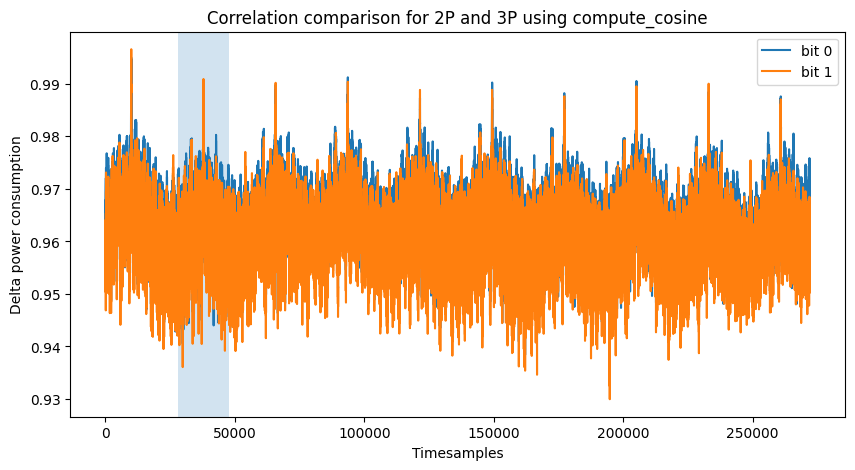

Template 0
  Window: 27870 - 47870
  Max in window: 0.99046135
Template 1
  Window: 27870 - 47870
  Max in window: 0.9909167
Score bit 0: 0.99046135
Score bit 1: 0.9909167
Recovered key bit: 1
Current scalar: 3


100%|██████████| 272100/272100 [04:36<00:00, 984.32it/s] 


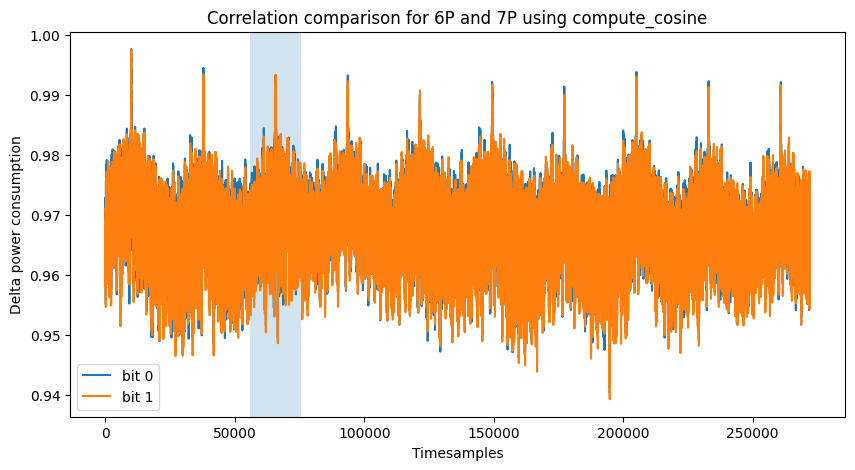

Template 0
  Window: 55740 - 75740
  Max in window: 0.9932789
Template 1
  Window: 55740 - 75740
  Max in window: 0.99332535
Score bit 0: 0.9932789
Score bit 1: 0.99332535
Recovered key bit: 1
Current scalar: 7


100%|██████████| 272100/272100 [04:39<00:00, 974.88it/s] 


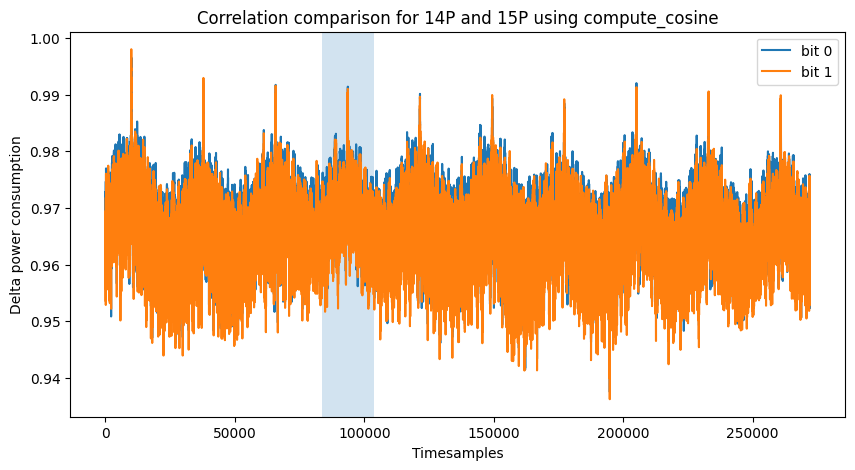

Template 0
  Window: 83610 - 103610
  Max in window: 0.9914382
Template 1
  Window: 83610 - 103610
  Max in window: 0.9910462
Score bit 0: 0.9914382
Score bit 1: 0.9910462
Recovered key bit: 0
Current scalar: 14


100%|██████████| 272100/272100 [04:36<00:00, 984.45it/s] 


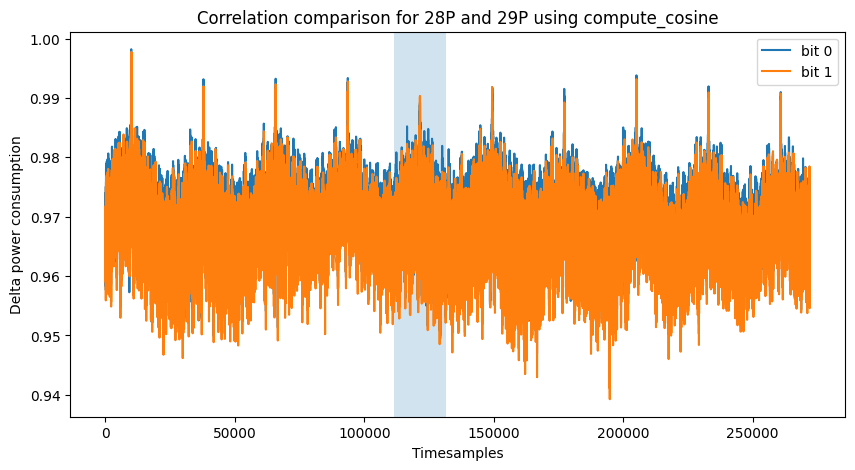

Template 0
  Window: 111480 - 131480
  Max in window: 0.9892337
Template 1
  Window: 111480 - 131480
  Max in window: 0.9903245
Score bit 0: 0.9892337
Score bit 1: 0.9903245
Recovered key bit: 1
Current scalar: 29


100%|██████████| 272100/272100 [04:40<00:00, 971.76it/s] 


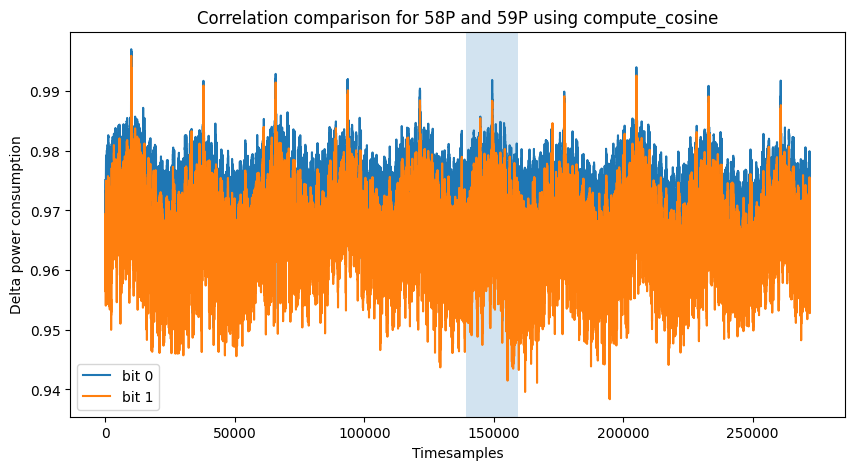

Template 0
  Window: 139350 - 159350
  Max in window: 0.9918862
Template 1
  Window: 139350 - 159350
  Max in window: 0.98840207
Score bit 0: 0.9918862
Score bit 1: 0.98840207
Recovered key bit: 0
Current scalar: 58


100%|██████████| 272100/272100 [04:22<00:00, 1035.60it/s]


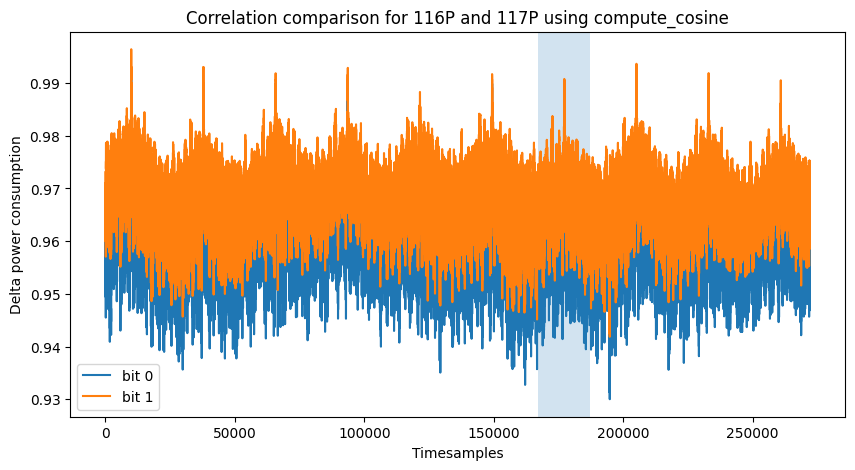

Template 0
  Window: 167220 - 187220
  Max in window: 0.9851924
Template 1
  Window: 167220 - 187220
  Max in window: 0.9907849
Score bit 0: 0.9851924
Score bit 1: 0.9907849
Recovered key bit: 1
Current scalar: 117


100%|██████████| 272100/272100 [03:54<00:00, 1161.22it/s]


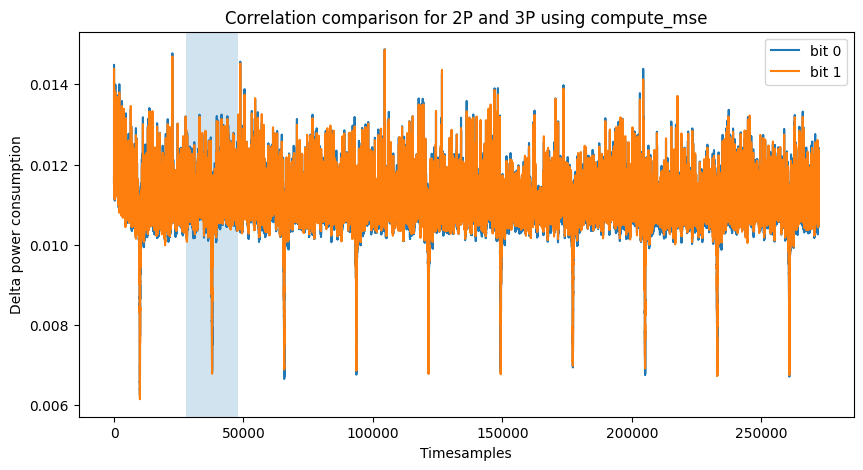

Template 0
  Window: 27870 - 47870
  Min in window: 0.006804409436881542
Template 1
  Window: 27870 - 47870
  Min in window: 0.006784006487578154
Score bit 0: 0.006804409436881542
Score bit 1: 0.006784006487578154
Recovered key bit: 1
Current scalar: 3


100%|██████████| 272100/272100 [03:58<00:00, 1141.78it/s]


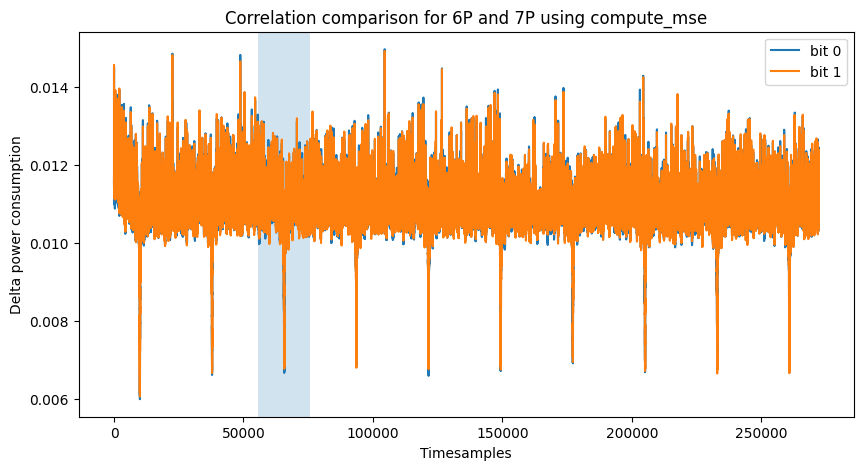

Template 0
  Window: 55740 - 75740
  Min in window: 0.006665097549557686
Template 1
  Window: 55740 - 75740
  Min in window: 0.00677040871232748
Score bit 0: 0.006665097549557686
Score bit 1: 0.00677040871232748
Recovered key bit: 0
Current scalar: 6


100%|██████████| 272100/272100 [04:05<00:00, 1106.22it/s]


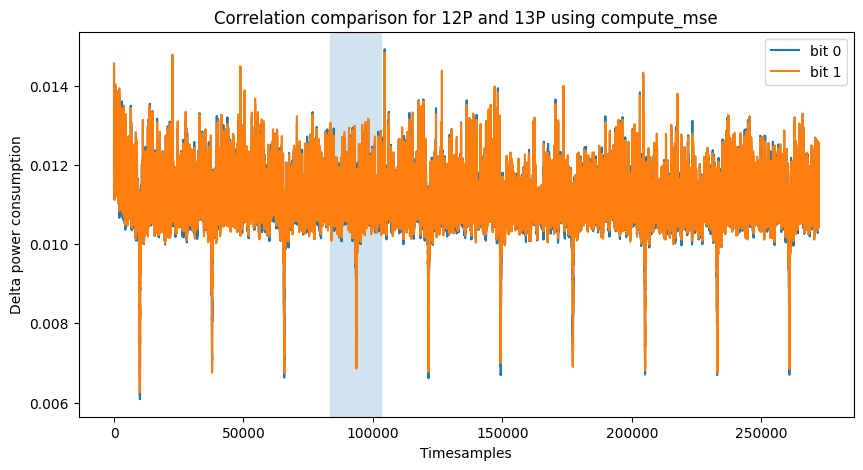

Template 0
  Window: 83610 - 103610
  Min in window: 0.006967443041503429
Template 1
  Window: 83610 - 103610
  Min in window: 0.006858556531369686
Score bit 0: 0.006967443041503429
Score bit 1: 0.006858556531369686
Recovered key bit: 1
Current scalar: 13


100%|██████████| 272100/272100 [03:57<00:00, 1146.35it/s]


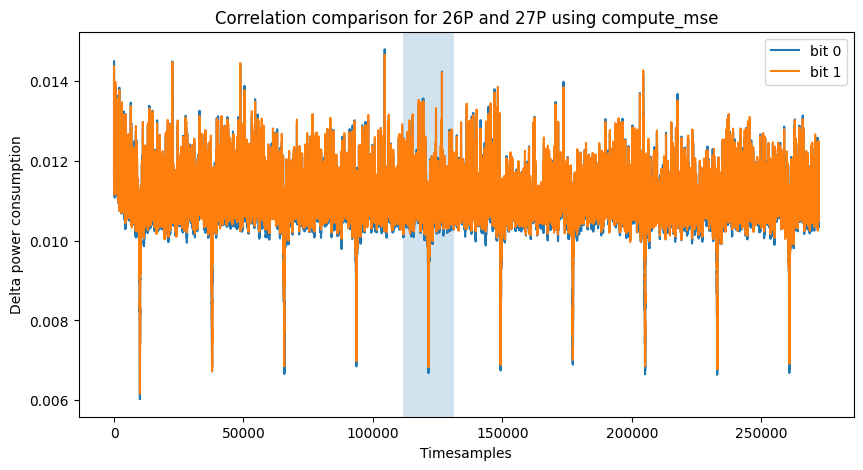

Template 0
  Window: 111480 - 131480
  Min in window: 0.006680799648165703
Template 1
  Window: 111480 - 131480
  Min in window: 0.0068268426693975925
Score bit 0: 0.006680799648165703
Score bit 1: 0.0068268426693975925
Recovered key bit: 0
Current scalar: 26


100%|██████████| 272100/272100 [03:47<00:00, 1193.50it/s]


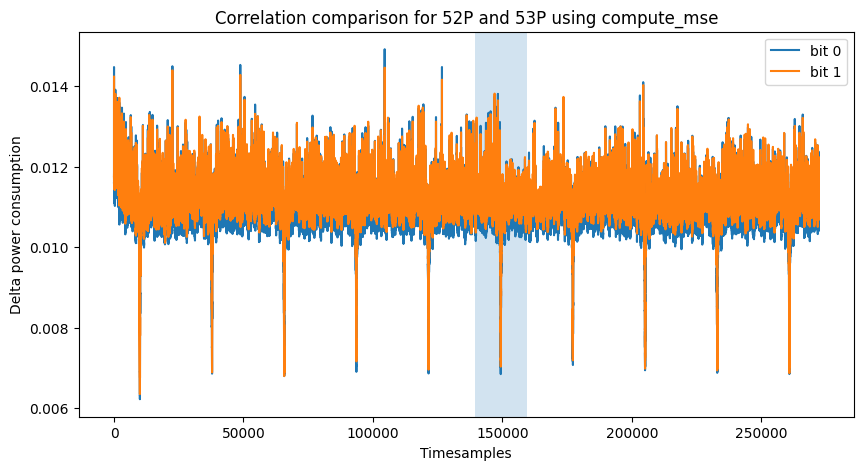

Template 0
  Window: 139350 - 159350
  Min in window: 0.006841644179075956
Template 1
  Window: 139350 - 159350
  Min in window: 0.00702760461717844
Score bit 0: 0.006841644179075956
Score bit 1: 0.00702760461717844
Recovered key bit: 0
Current scalar: 52


100%|██████████| 272100/272100 [03:47<00:00, 1197.28it/s]


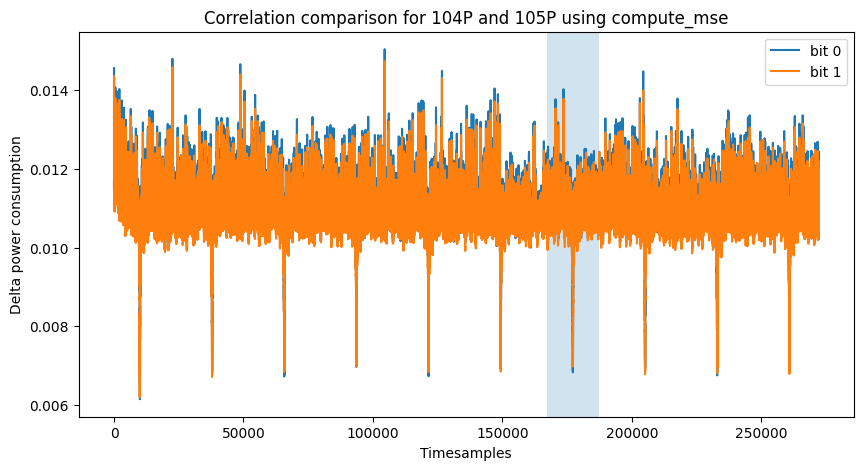

Template 0
  Window: 167220 - 187220
  Min in window: 0.006832933984696865
Template 1
  Window: 167220 - 187220
  Min in window: 0.0069840047508478165
Score bit 0: 0.006832933984696865
Score bit 1: 0.0069840047508478165
Recovered key bit: 0
Current scalar: 104


100%|██████████| 272100/272100 [03:53<00:00, 1164.69it/s]


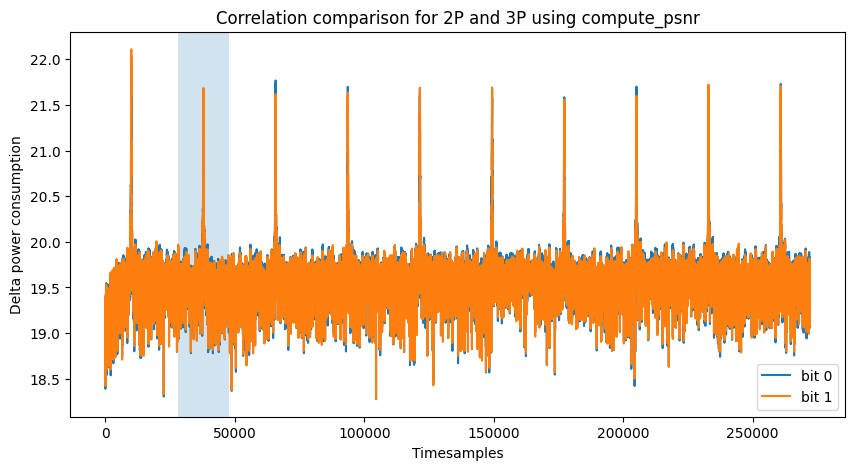

Template 0
  Window: 27870 - 47870
  Max in window: 21.672095617807457
Template 1
  Window: 27870 - 47870
  Max in window: 21.68513745433234
Score bit 0: 21.672095617807457
Score bit 1: 21.68513745433234
Recovered key bit: 1
Current scalar: 3


100%|██████████| 272100/272100 [03:56<00:00, 1150.55it/s]


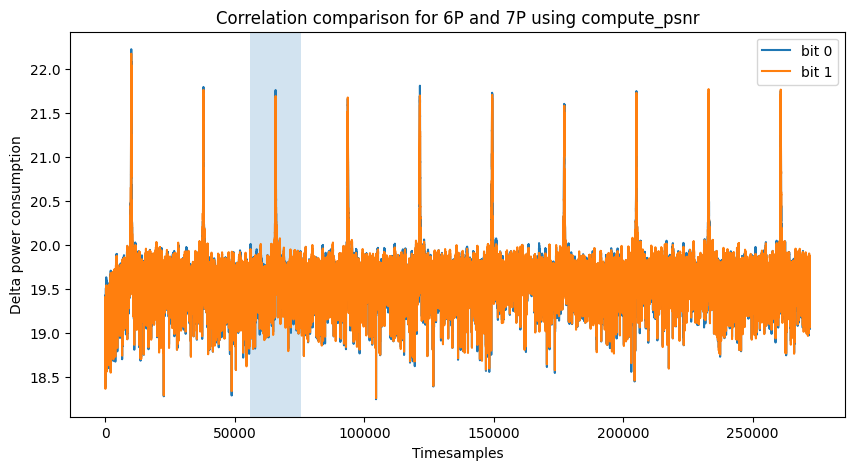

Template 0
  Window: 55740 - 75740
  Max in window: 21.76193489922352
Template 1
  Window: 55740 - 75740
  Max in window: 21.693851132719093
Score bit 0: 21.76193489922352
Score bit 1: 21.693851132719093
Recovered key bit: 0
Current scalar: 6


100%|██████████| 272100/272100 [04:06<00:00, 1104.19it/s]


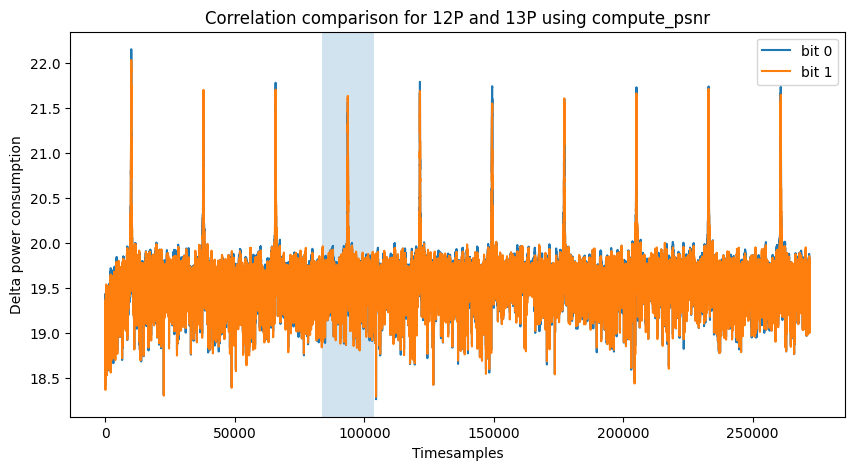

Template 0
  Window: 83610 - 103610
  Max in window: 21.569265729357014
Template 1
  Window: 83610 - 103610
  Max in window: 21.637672773580835
Score bit 0: 21.569265729357014
Score bit 1: 21.637672773580835
Recovered key bit: 1
Current scalar: 13


100%|██████████| 272100/272100 [04:07<00:00, 1099.20it/s]


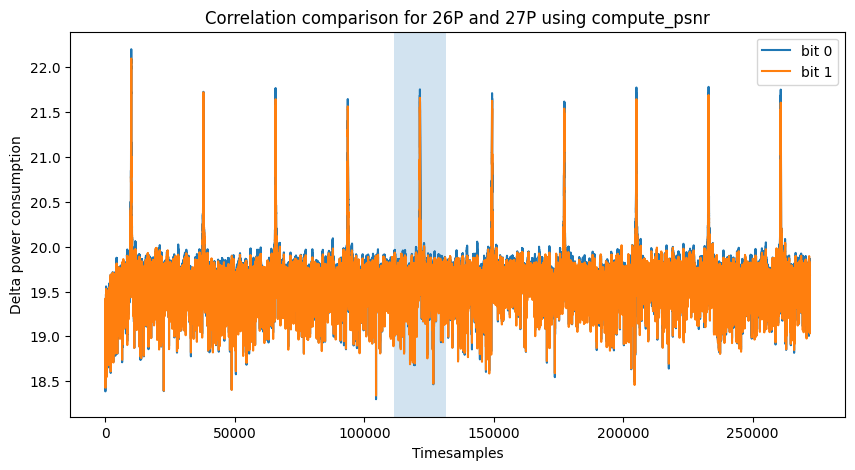

Template 0
  Window: 111480 - 131480
  Max in window: 21.75171552194925
Template 1
  Window: 111480 - 131480
  Max in window: 21.657801057318572
Score bit 0: 21.75171552194925
Score bit 1: 21.657801057318572
Recovered key bit: 0
Current scalar: 26


100%|██████████| 272100/272100 [04:05<00:00, 1106.96it/s]


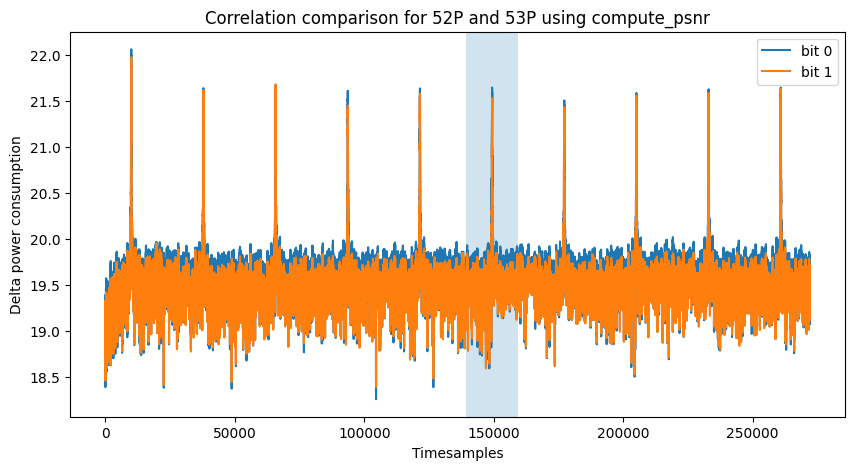

Template 0
  Window: 139350 - 159350
  Max in window: 21.648395163950692
Template 1
  Window: 139350 - 159350
  Max in window: 21.531926805017207
Score bit 0: 21.648395163950692
Score bit 1: 21.531926805017207
Recovered key bit: 0
Current scalar: 52


100%|██████████| 272100/272100 [03:53<00:00, 1164.54it/s]


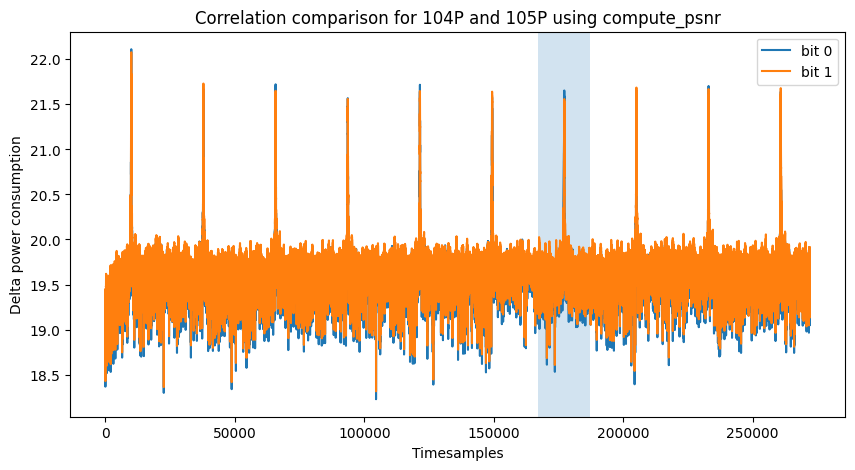

Template 0
  Window: 167220 - 187220
  Max in window: 21.653927751239934
Template 1
  Window: 167220 - 187220
  Max in window: 21.558954738748966
Score bit 0: 21.653927751239934
Score bit 1: 21.558954738748966
Recovered key bit: 0
Current scalar: 104
The found key: [[0. 1. 1. 0. 1. 0. 1. 1.]
 [0. 1. 0. 1. 0. 0. 0. 1.]
 [0. 1. 0. 1. 0. 0. 0. 1.]]


In [7]:
# Do the sequential key bit recovery

keybits = 6

similarity_methods = [compute_cosine,
    compute_mse,
    compute_psnr]
recovered_key = np.ones(shape=(len(similarity_methods), keybits + 2))  # Initialize with ones to set the first bit for each method to 1
recovered_key[:, 0] = 0  # Set the MSB to 1 for all methods

poi_start = 10000
poi_end = 37900
step_size = 1

for j, method in enumerate(similarity_methods):
    scalar = 1
    for iteration, keybit_to_guess in enumerate(range(0, keybits*2, 2)):

        # Determine input points based on previous key bits
        # [It is an online attack, but as the dataset is already there, assume that new input points are calculated here]
        
        # Collect traces
        # [It is an online attack, but as the dataset is already there, assume that new input points are put in the code & traces are collected]

        # Create templates from the collected traces
        template0_targetbit = template_traces[2*iteration, :]
        template1_targetbit = template_traces[2*iteration + 1, :]
        templates_targetbit = [template0_targetbit, template1_targetbit]

    
        # Find peaks automatically
        corr_array = np.abs(pattern_match(target_trace, template0_targetbit, compute_correlation, poi_start, poi_end, step=step_size))
        # Perform pattern matching with templates to target trace based on Correlation
        window_start, window_end = get_window(corr_array, iteration)

        comparison_array0 = pattern_match(target_trace, template0_targetbit, method, poi_start, poi_end, step=step_size)
        comparison_array1 = pattern_match(target_trace, template1_targetbit, method, poi_start, poi_end, step=step_size)
        
        np.savez("./analysis similarities/ota3_bitpos{}_{}.npz".format(iteration, method.__name__), comparison_0 = comparison_array0, comparison_1 = comparison_array1)

        
        plot_similarity([comparison_array0,comparison_array1], scalar, window_start, window_end, method)
        
        # Determine the key bit based on the pattern matching results
        best_keyguess, scalar = determine_keybit([comparison_array0, comparison_array1], window_start, window_end, scalar, method)

        recovered_key[j, iteration+1] = best_keyguess
        print("Recovered key bit:", best_keyguess)
        print("Current scalar:", scalar)

print("The found key: " + str(recovered_key))